# Лабораторная работа 1. Линейная регрессия и факторный анализ

**Датасет:** [Diamonds](https://www.kaggle.com/datasets/shivam2503/diamonds) (характеристики и цены бриллиантов)
**Файл данных:** `data/diamonds.csv`
**Целевая переменная:** `price` — цена бриллианта, доллары США

## 1. Введение

**Цель работы** — освоить линейную регрессию на реальных данных: подготовить признаки, проверить их на мультиколлинеарность, обучить обычную, гребневую и лассо-регрессию, оценить качество и посмотреть, что меняется после сжатия признаков методом главных компонент.

**Задачи:**

1. Загрузить датасет и описать его состав.
2. Провести первичный анализ и построить распределения признаков и целевой переменной.
3. Очистить данные и закодировать категориальные признаки.
4. Построить корреляционную матрицу и оценить мультиколлинеарность коэффициентом VIF.
5. Разделить выборку на обучающую и тестовую (80/20), обучить линейную, гребневую и лассо-регрессию с кросс-валидацией и сравнить RMSE, R² и MAPE.
6. По графикам остатков (с линией на уровне нуля) проверить, постоянна ли дисперсия ошибок.
7. Стандартизировать признаки и применить PCA, обосновав число компонент графиком каменистой осыпи.
8. Повторить обучение трёх моделей уже на главных компонентах и сравнить метрики с моделями на исходных признаках.

Цена — непрерывная величина, поэтому в работе используется регрессия, а не логистическая модель.

## 2. Описание датасета и первичный анализ

Набор Diamonds содержит около 54 тысяч камней. Это тот же набор, что входит в пакет ggplot2 и выложен на Kaggle. В репозитории нет пропусков в явном виде, но нулевые и неправдоподобные размеры встречаются: их нужно найти при первичном анализе, а не считать признак «чистым» только потому, что `isnull()` вернул нули.

Столбцы:

- `carat` — масса, караты;
- `cut` — качество огранки: Fair, Good, Very Good, Premium, Ideal (от худшей к лучшей);
- `color` — цвет: J (заметный оттенок) … D (бесцветный, лучший);
- `clarity` — чистота: I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF (от худшей к лучшей);
- `depth` — общая глубина, % от среднего диаметра: \(2z/(x+y)\);
- `table` — ширина верхней площадки, % от диаметра;
- `price` — цена, USD, целевая переменная;
- `x`, `y`, `z` — длина, ширина и глубина, мм.

### 2.1. Загрузка данных

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("data/diamonds.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("Lab1_Linear_Regression") / "data" / "diamonds.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Размерность: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов")
print(f"Файл: {DATA_PATH.resolve()}")
display(df_raw.head())

Размерность: 53940 строк, 10 столбцов
Файл: D:\sharaga\AIslop\Lab1_Linear_Regression\data\diamonds.csv


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Загружено 53 940 наблюдений и 10 столбцов. Каждая строка — один бриллиант, отдельного идентификатора нет. Цена записана целым числом долларов, размеры и масса — вещественные. Категории `cut`, `color` и `clarity` пока текстовые: в линейную модель их можно подать только после кодирования.

Фиксация `RANDOM_STATE = 42` нужна, чтобы разбиение 80/20 и фолды кросс-валидации повторялись при перезапуске ноутбука.

### 2.2. Пропуски, дубликаты и описательная статистика

In [3]:
print("Пропущенные значения по столбцам:")
display(df_raw.isnull().sum().to_frame("пропуски"))
print(f"Полных дубликатов: {int(df_raw.duplicated().sum())}")

bad_geom = (df_raw["x"] <= 0) | (df_raw["y"] <= 0) | (df_raw["z"] <= 0)
extreme_geom = (df_raw["x"] >= 20) | (df_raw["y"] >= 20) | (df_raw["z"] >= 20)
print(f"Строк с нулевым размером x, y или z: {int(bad_geom.sum())}")
print(f"Строк с размером 20 мм и больше: {int(extreme_geom.sum())}")

display(df_raw.describe().T.round(2))

print("Категории огранки, цвета и чистоты:")
for col in ["cut", "color", "clarity"]:
    display(df_raw[col].value_counts().rename(col).to_frame())

Пропущенные значения по столбцам:


,пропуски
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


Полных дубликатов: 146
Строк с нулевым размером x, y или z: 20
Строк с размером 20 мм и больше: 3


,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.80,0.47,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.75,1.43,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.46,2.23,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.80,3989.44,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.73,1.12,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.73,1.14,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.54,0.71,0.0,2.91,3.53,4.04,31.80


Категории огранки, цвета и чистоты:


,cut
cut,
Ideal,21551
Premium,13791
Very Good,12082
Good,4906
Fair,1610


,color
color,
G,11292
E,9797
F,9542
H,8304
D,6775
I,5422
J,2808


,clarity
clarity,
SI1,13065
VS2,12258
SI2,9194
VS1,8171
VVS2,5066
VVS1,3655
IF,1790
I1,741


Явных пропусков нет ни в одном столбце. Это не значит, что измерения полные: у 20 камней хотя бы один из размеров `x`, `y`, `z` равен нулю. Нулевой миллиметр при положительной массе — ошибка записи, а не физический размер. Ещё три строки содержат неправдоподобные размеры (в сырых данных ширина доходит до 58,9 мм, глубина до 31,8 мм при обычных значениях около 4–7 мм). Такие точки нельзя оставлять: они раздувают дисперсию и корреляции размеров.

Полных дубликатов 146. Одинаковые строки не добавляют новой информации и при обучении получают лишний вес, поэтому на этапе очистки они будут удалены.

Цена сильно скошена вправо: минимум 326 долларов, медиана заметно ниже среднего (среднее около 3 933 долларов, максимум 18 823). Та же асимметрия видна у массы. Большинство камней относится к огранке Ideal и Premium и к средним группам чистоты SI1/VS2. Редкие классы Fair и I1 есть, но их мало, поэтому выводы по ним будут менее устойчивыми.

### 2.3. Распределения признаков и целевой переменной

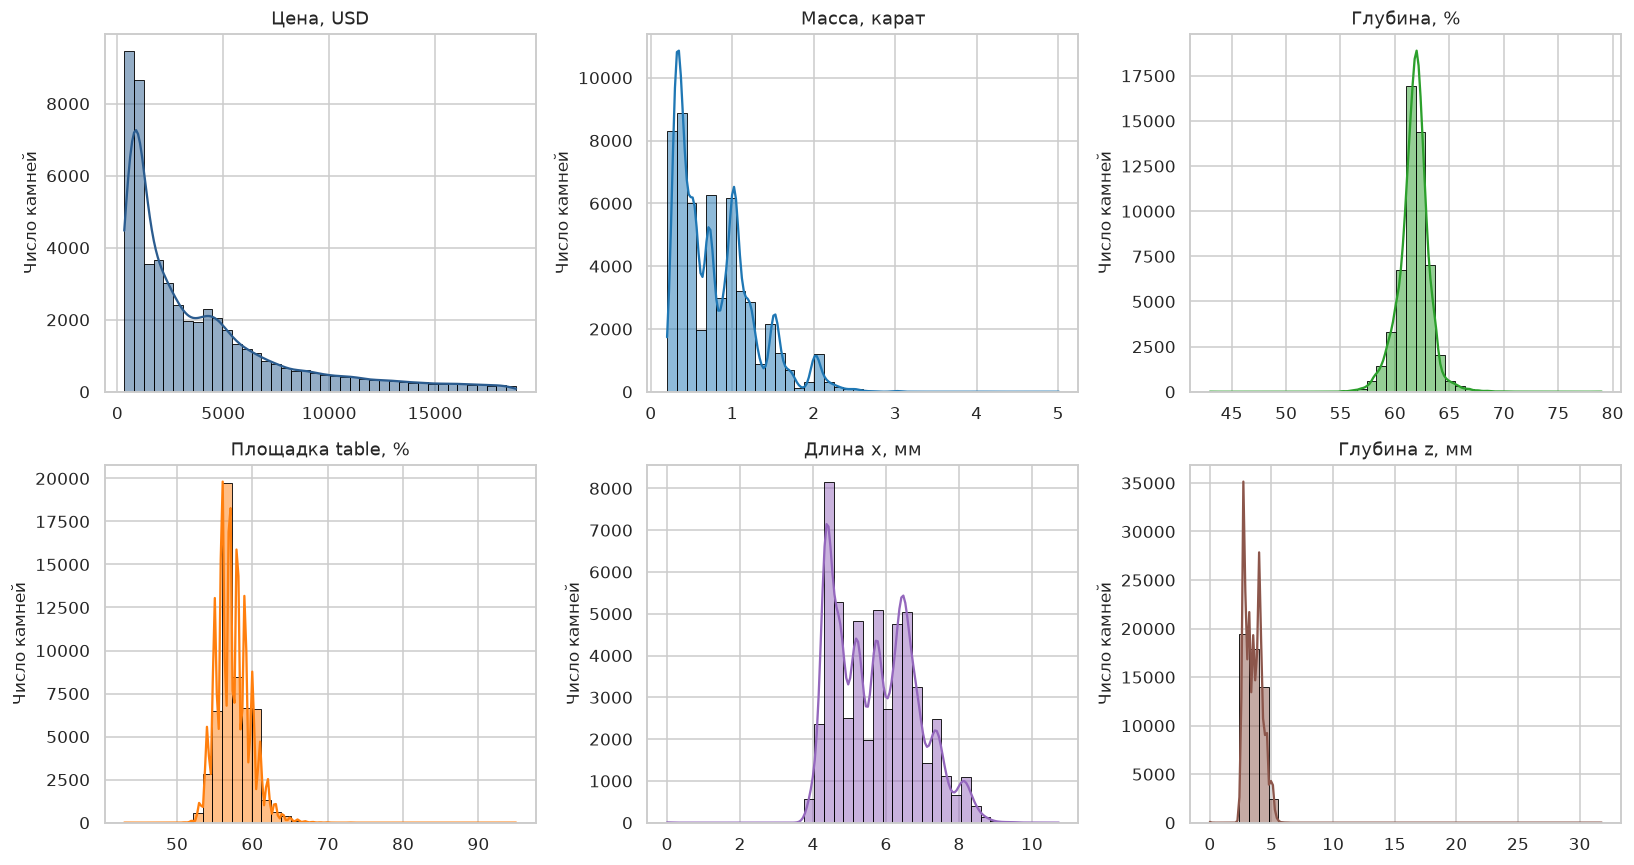

In [4]:
df_viz = df_raw.copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
hist_spec = [
    (axes[0, 0], df_viz["price"], "Цена, USD", "#2b5c8f"),
    (axes[0, 1], df_viz["carat"], "Масса, карат", "#1f77b4"),
    (axes[0, 2], df_viz["depth"], "Глубина, %", "#2ca02c"),
    (axes[1, 0], df_viz["table"], "Площадка table, %", "#ff7f0e"),
    (axes[1, 1], df_viz["x"], "Длина x, мм", "#9467bd"),
    (axes[1, 2], df_viz["z"], "Глубина z, мм", "#8c564b"),
]
for ax, series, title, color in hist_spec:
    sns.histplot(series, bins=40, kde=True, ax=ax, color=color, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Число камней")
plt.tight_layout()
plt.show()

Цена и масса имеют длинный правый хвост: основная масса камней дешевле 5 000 долларов и легче полутора карат, но редкие крупные бриллианты тянут среднее вверх. Для линейной модели это важный сигнал. Квадратичная ошибка будет определяться дорогими камнями, а процентная ошибка — дешёвыми, поэтому RMSE и MAPE дальше могут разойтись в выводах.

Глубина и ширина площадки, наоборот, сосредоточены в узком диапазоне (глубина в основном 60–64%). Это проценты от диаметра, а не самостоятельный «размер камня». Длина и глубина в миллиметрах повторяют форму распределения массы: размеры и карат описывают почти одну и ту же величину — насколько камень крупный. На гистограмме z при этом виден отдельный всплеск в нуле и редкие значения около 30 мм. Это не глубина реальных камней, а сбои записи: перед обучением такие строки будут удалены.

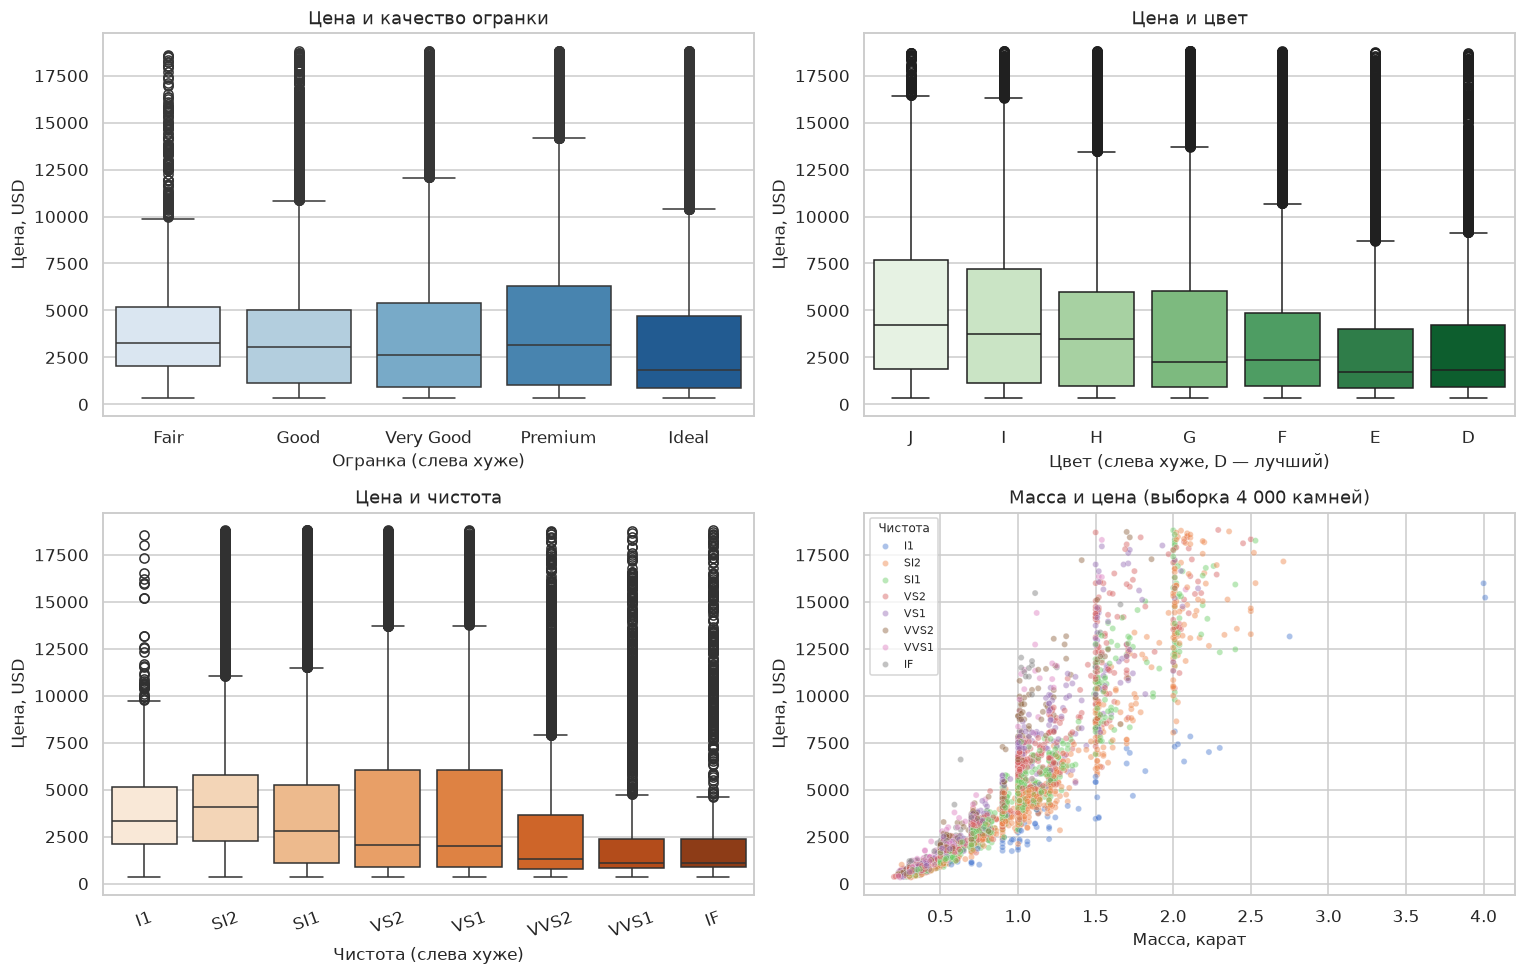

,"медиана цены, cut","средняя масса, cut"
cut,,
Fair,3282.0,1.0
Good,3050.5,0.8
Very Good,2648.0,0.8
Premium,3185.0,0.9
Ideal,1810.0,0.7


,медиана цены,средняя масса
color,,
J,4234.0,1.2
I,3730.0,1.0
H,3460.0,0.9
G,2242.0,0.8
F,2343.5,0.7
E,1739.0,0.7
D,1838.0,0.7


In [ ]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.boxplot(data=df_viz, x="cut", y="price", order=cut_order, hue="cut", hue_order=cut_order,
            palette="Blues", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Цена и качество огранки")
axes[0, 0].set_xlabel("Огранка (слева хуже)")
axes[0, 0].set_ylabel("Цена, USD")

sns.boxplot(data=df_viz, x="color", y="price", order=color_order, hue="color", hue_order=color_order,
            palette="Greens", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Цена и цвет")
axes[0, 1].set_xlabel("Цвет (слева хуже, D — лучший)")
axes[0, 1].set_ylabel("Цена, USD")

sns.boxplot(data=df_viz, x="clarity", y="price", order=clarity_order, hue="clarity", hue_order=clarity_order,
            palette="Oranges", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Цена и чистота")
axes[1, 0].set_xlabel("Чистота (слева хуже)")
axes[1, 0].set_ylabel("Цена, USD")
axes[1, 0].tick_params(axis="x", rotation=20)

sample = df_viz.sample(n=4000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="carat", y="price", hue="clarity", hue_order=clarity_order,
                alpha=0.45, s=16, ax=axes[1, 1])
axes[1, 1].set_title("Масса и цена (выборка 4 000 камней)")
axes[1, 1].set_xlabel("Масса, карат")
axes[1, 1].set_ylabel("Цена, USD")
axes[1, 1].legend(title="Чистота", fontsize=7, title_fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

median_tbl = pd.DataFrame({
    "медиана цены, cut": df_viz.groupby("cut")["price"].median().reindex(cut_order),
    "средняя масса, cut": df_viz.groupby("cut")["carat"].mean().reindex(cut_order).round(3),
})
display(median_tbl.round(1))
display(pd.DataFrame({
    "медиана цены": df_viz.groupby("color")["price"].median().reindex(color_order),
    "средняя масса": df_viz.groupby("color")["carat"].mean().reindex(color_order).round(3),
}).round(1))

Связь массы и цены на диаграмме рассеяния близка к возрастающей и слегка выпуклой: каждый следующий карат добавляет к цене больше, чем предыдущий. Цвет точек (чистота) при одной и той же массе сдвигает цену, но этот сдвиг намного слабее, чем эффект размера.

Ящики с усами без учёта массы обманывают. Медианная цена огранки Ideal ниже, чем у Fair, а бесцветные камни D дешевле камней цвета J. Так происходит не потому, что качество снижает цену, а потому, что лучшие по цвету и огранке камни в этой выборке в среднем легче. Fair в среднем тяжелее 1 карата, Ideal — около 0,70 карата; цвет J в среднем тяжелее D. Пока масса не зафиксирована, сравнивать группы по цене бессмысленно. Именно поэтому дальше нужен не только график, но и регрессия, где масса и качество стоят в одной модели.

## 3. Подготовка данных

### 3.1. Очистка и кодирование категорий

In [5]:
CUT_ORDER = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
COLOR_ORDER = ["J", "I", "H", "G", "F", "E", "D"]
CLARITY_ORDER = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

df = df_raw.copy()
n_before = len(df)
df = df[(df["x"] > 0) & (df["y"] > 0) & (df["z"] > 0)].copy()
df = df[(df["x"] < 20) & (df["y"] < 20) & (df["z"] < 20)].copy()
n_geom = n_before - len(df)
n_before_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_dup = n_before_dup - len(df)

df["cut_score"] = df["cut"].map({name: i for i, name in enumerate(CUT_ORDER)})
df["color_score"] = df["color"].map({name: i for i, name in enumerate(COLOR_ORDER)})
df["clarity_score"] = df["clarity"].map({name: i for i, name in enumerate(CLARITY_ORDER)})

feature_cols = ["carat", "cut_score", "color_score", "clarity_score", "depth", "table", "x", "y", "z"]
target_col = "price"

print(f"Удалено строк с некорректной геометрией: {n_geom}")
print(f"Удалено дубликатов: {n_dup}")
print(f"Размер после очистки: {df.shape[0]} строк")
print("Шкалы: больший балл = лучше качество. Огранка 0..4, цвет 0..6, чистота 0..7.")
display(df[feature_cols + [target_col]].head())
print("Незакодированных категорий:", int(df[["cut_score", "color_score", "clarity_score"]].isna().sum().sum()))

Удалено строк с некорректной геометрией: 23
Удалено дубликатов: 145
Размер после очистки: 53772 строк
Шкалы: больший балл = лучше качество. Огранка 0..4, цвет 0..6, чистота 0..7.


,carat,cut_score,color_score,clarity_score,depth,table,x,y,z,price
0,0.23,4,5,1,61.5,55.0,3.95,3.98,2.43,326
1,0.21,3,5,2,59.8,61.0,3.89,3.84,2.31,326
2,0.23,1,5,4,56.9,65.0,4.05,4.07,2.31,327
3,0.29,3,1,3,62.4,58.0,4.20,4.23,2.63,334
4,0.31,1,0,1,63.3,58.0,4.34,4.35,2.75,335


Незакодированных категорий: 0


На этом шаге удалены 23 строки с нулевой или нефизичной геометрией и 145 дубликатов, оставшихся после этого фильтра. В модели остаётся 53 772 камня.

Огранка, цвет и чистота — упорядоченные шкалы, а не номинальные метки. Поэтому они закодированы целыми баллами от худшего качества к лучшему, а не набором дамми-переменных. Порядковый код сохраняет направление «лучше / хуже» одним столбцом и не раздувает матрицу. Обратная сторона такая: модель считает шаг между соседними градациями одинаковым. Для лабораторной линейной регрессии это приемлемое упрощение; если бы шаг между SI2 и SI1 заметно отличался от шага между VVS1 и IF, понадобилось бы one-hot кодирование.

Текстовые столбцы `cut`, `color`, `clarity` в матрицу признаков не входят. Целевая переменная `price` остаётся в долларах.

### 3.2. Матрица корреляций

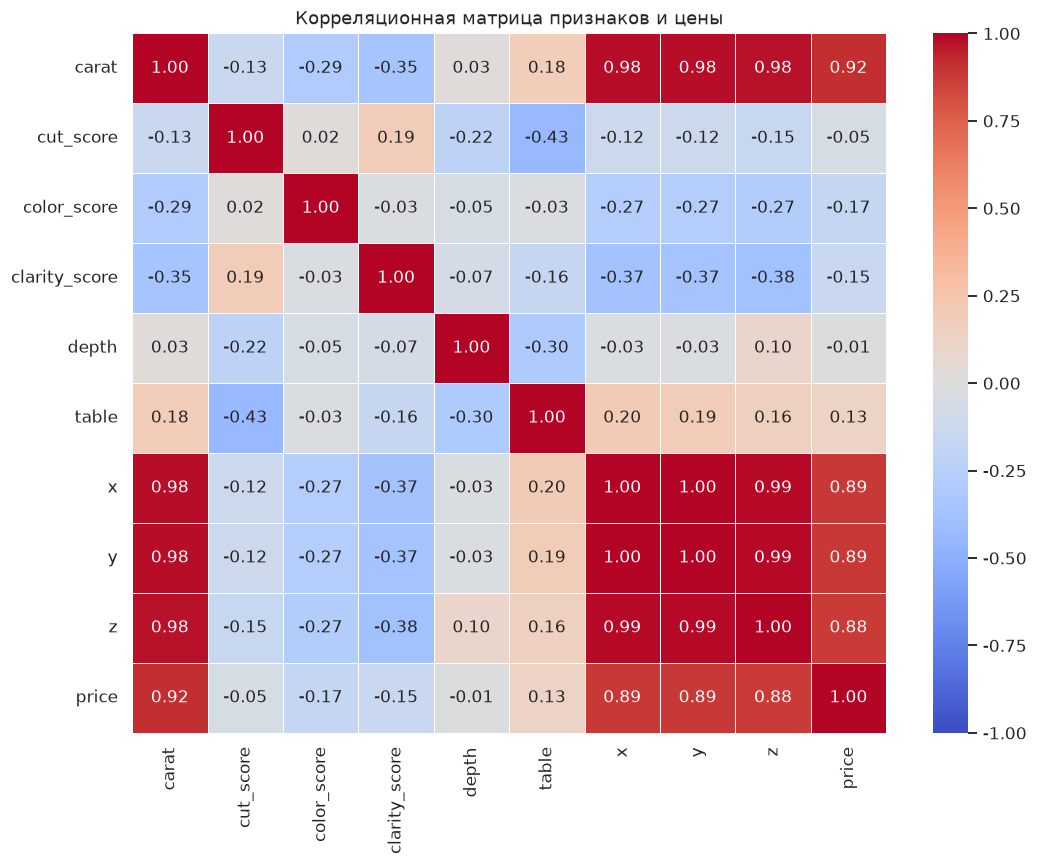

,корреляция с price
carat,0.922
y,0.889
x,0.887
z,0.882
color_score,-0.172
clarity_score,-0.146
table,0.127
cut_score,-0.052
depth,-0.011


In [6]:
corr_cols = feature_cols + [target_col]
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.4)
plt.title("Корреляционная матрица признаков и цены")
plt.tight_layout()
plt.show()

target_corr = corr[target_col].drop(target_col).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.rename("корреляция с price").to_frame().round(3))

С ценой сильнее всего связана масса (корреляция около 0,92) и три линейных размера (около 0,88–0,89). Между собой `carat`, `x`, `y` и `z` коррелируют на 0,98–0,99. Это ожидаемо: масса камня почти определяется его объёмом. Для регрессии такой блок признаков опасен. Модель видит четыре почти одинаковых столбца и не может надёжно разделить их вклады.

Корреляции качества с ценой слабые и отрицательные: у цвета около −0,17, у чистоты около −0,15, у огранки около нуля. Это тот же эффект, что на ящиках с усами. Более качественные камни в выборке мельче, а мелкая масса перевешивает прибавку за качество. Отрицательный знак в матрице корреляций нельзя переносить на коэффициент регрессии: там масса будет контролироваться отдельно.

Глубина `depth` с ценой практически не связана (корреляция около нуля), но она алгебраически собрана из `x`, `y` и `z`. Слабая связь с целью не отменяет мультиколлинеарность с размерами. Её как раз должен показать VIF, а не парная корреляция с ценой.

### 3.3. Диагностика мультиколлинеарности: VIF

,Признак,VIF
0,y,501.64
1,x,499.99
2,z,435.31
3,carat,25.11
4,depth,7.93
5,table,1.63
6,cut_score,1.50
7,clarity_score,1.24
8,color_score,1.12


Признаков с VIF > 5: 5
Признаков с VIF > 10: 4


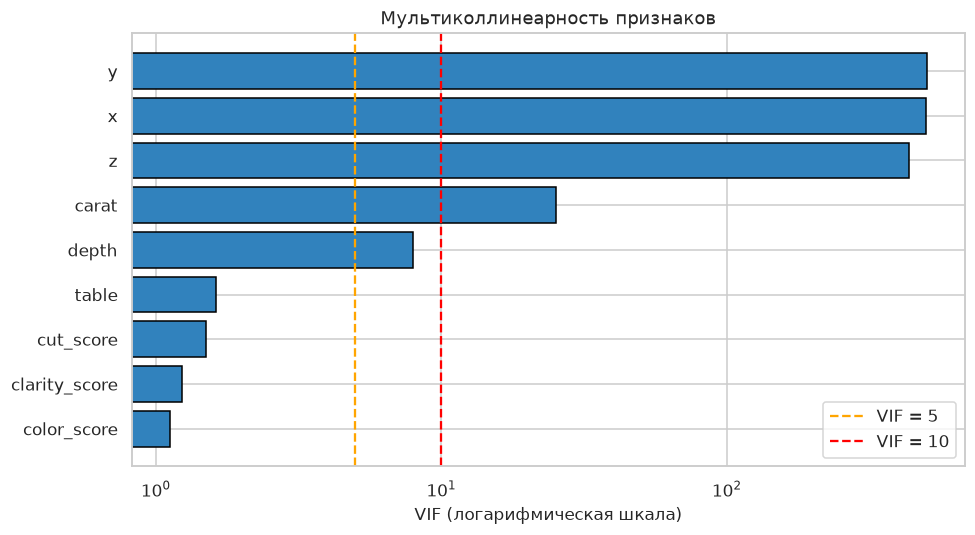

In [7]:
X_all = df[feature_cols]
scaler_vif = StandardScaler()
X_vif = pd.DataFrame(scaler_vif.fit_transform(X_all), columns=feature_cols)

vif_df = pd.DataFrame({
    "Признак": feature_cols,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)

display(vif_df.round(2))
print(f"Признаков с VIF > 5: {int((vif_df['VIF'] > 5).sum())}")
print(f"Признаков с VIF > 10: {int((vif_df['VIF'] > 10).sum())}")

plt.figure(figsize=(9, 5))
plt.barh(vif_df["Признак"], vif_df["VIF"], color="#3182bd", edgecolor="black")
plt.axvline(5, color="orange", ls="--", lw=1.5, label="VIF = 5")
plt.axvline(10, color="red", ls="--", lw=1.5, label="VIF = 10")
plt.xscale("log")
plt.xlabel("VIF (логарифмическая шкала)")
plt.title("Мультиколлинеарность признаков")
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

VIF показывает, насколько признак линейно восстанавливается по остальным. Ориентиры такие: около 1 — пересечения почти нет, выше 5 — заметная мультиколлинеарность, выше 10 — сильная, оценки МНК становятся неустойчивыми.

Здесь порог 10 превышен у четырёх признаков размера. VIF длины, ширины и глубины составляет сотни (около 400–500), у массы — около 25. Глубина в процентах тоже выше 5 (около 8), хотя с ценой она не коррелирует: её «объясняют» сами миллиметры, из которых она посчитана. Баллы огранки, цвета и чистоты имеют VIF около 1,1–1,6, то есть между собой почти не дублируются.

Практический вывод: прогноз цены по полному набору ещё может получиться точным, потому что новые камни лежат в той же области, где масса и размеры согласованы. Интерпретировать отдельные коэффициенты при `x`, `y`, `z` и `carat` уже нельзя. Это как раз задача для регуляризации и для PCA. Шкала графика логарифмическая, иначе столбцы с VIF около 1 на фоне значений в сотни были бы не видны.

### 3.4. Разделение выборки и стандартизация

In [8]:
X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Обучающая выборка: {X_train.shape[0]} строк, {X_train.shape[1]} признаков")
print(f"Тестовая выборка:  {X_test.shape[0]} строк")
print(f"Доля теста: {X_test.shape[0] / len(df):.1%}")
print(f"Средняя цена train / test: {y_train.mean():.1f} / {y_test.mean():.1f}")

Обучающая выборка: 43017 строк, 9 признаков
Тестовая выборка:  10755 строк
Доля теста: 20.0%
Средняя цена train / test: 3938.5 / 3901.7


Выборка разделена в отношении 80/20: 43 017 камней на обучение и 10 755 на проверку. Средние цены в двух частях близки, грубого перекоса по цели нет.

`StandardScaler` обучается только на тренировочной части. Тест преобразуется теми же средними и дисперсиями. Если масштабировать всю таблицу до разбиения, информация теста попадёт в предобработку.

Стандартизация нужна по двум причинам. Во-первых, карат (порядка 1), глубина (около 62) и цена живут в разных масштабах, а штраф Ridge и Lasso зависит от величины коэффициента. Во-вторых, PCA ищет направления максимальной дисперсии: без стандартизации миллиметры и проценты задавили бы массу только из-за единиц измерения. Для обычного МНК масштаб не меняет прогнозы, но делает коэффициенты сопоставимыми: каждый вес отвечает одному стандартному отклонению признака.

## 4. Ход работы

### 4.1. Линейная, гребневая и лассо-регрессия на исходных признаках

На стандартизированных признаках оцениваются три модели.

Обычная линейная регрессия минимизирует сумму квадратов остатков. Гребневая (Ridge) добавляет штраф \(\alpha \sum \beta_j^2\), лассо — штраф \(\alpha \sum |\beta_j|\). Штраф не даёт коэффициентам при почти одинаковых признаках разъезжаться в разные стороны. У лассо есть дополнительное свойство: при достаточно большом \(\alpha\) часть коэффициентов становится нулевой.

Параметр \(\alpha\) не задаётся вручную. Для Ridge и Lasso он выбирается 5-блочной кросс-валидацией по сетке `np.logspace(-2, 3, 30)` только на обучающей выборке. После выбора \(\alpha\) качество ещё раз проверяется 5-блочной кросс-валидацией по R² и отдельным прогоном на отложенном тесте. Метрики теста:

- RMSE — корень из средней квадратичной ошибки, в долларах, в той же шкале, что и цена;
- R² — доля дисперсии цены, объяснённая моделью;
- MAPE — средняя абсолютная процентная ошибка.

In [9]:
alphas = np.logspace(-2, 3, 30)
ridge_cv = RidgeCV(alphas=alphas, cv=5).fit(X_train_scaled, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=RANDOM_STATE, max_iter=20000).fit(X_train_scaled, y_train)
ridge_alpha = float(ridge_cv.alpha_)
lasso_alpha = float(lasso_cv.alpha_)
print(f"Ridge: alpha = {ridge_alpha:.4f}")
print(f"Lasso: alpha = {lasso_alpha:.4f}")

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate_models(models, X_tr, X_te, y_tr, y_te, space_name):
    rows = []
    fitted = {}
    preds = {}
    for name, model in models.items():
        cv_r2 = cross_val_score(model, X_tr, y_tr, cv=kf, scoring="r2")
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        row = {
            "Модель": name,
            "Пространство": space_name,
            "R2_CV": float(cv_r2.mean()),
            "R2_CV_std": float(cv_r2.std()),
            "R2_Test": float(r2_score(y_te, y_pred)),
            "RMSE_Test": float(np.sqrt(mean_squared_error(y_te, y_pred))),
            "MAPE_Test_%": float(mean_absolute_percentage_error(y_te, y_pred) * 100),
            "Отрицательных прогнозов": int((y_pred < 0).sum()),
        }
        rows.append(row)
        fitted[name] = model
        preds[name] = y_pred
        print(
            f"{name:<8} | R2(CV)={row['R2_CV']:.4f}±{row['R2_CV_std']:.4f} | "
            f"R2(test)={row['R2_Test']:.4f} | RMSE={row['RMSE_Test']:.1f} | "
            f"MAPE={row['MAPE_Test_%']:.2f}% | отриц. прогнозов={row['Отрицательных прогнозов']}"
        )
    return pd.DataFrame(rows), fitted, preds


models_orig = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=ridge_alpha, random_state=RANDOM_STATE),
    "Lasso": Lasso(alpha=lasso_alpha, random_state=RANDOM_STATE, max_iter=20000),
}
results_orig, fitted_orig, preds_orig = evaluate_models(
    models_orig, X_train_scaled, X_test_scaled, y_train, y_test,
    space_name="Исходные признаки",
)
display(results_orig.round(4))

Ridge: alpha = 5.7362
Lasso: alpha = 0.2395
Linear   | R2(CV)=0.9087±0.0028 | R2(test)=0.9048 | RMSE=1215.8 | MAPE=43.69% | отриц. прогнозов=888
Ridge    | R2(CV)=0.9087±0.0028 | R2(test)=0.9049 | RMSE=1215.7 | MAPE=43.72% | отриц. прогнозов=893
Lasso    | R2(CV)=0.9087±0.0028 | R2(test)=0.9048 | RMSE=1215.8 | MAPE=43.69% | отриц. прогнозов=891


,Модель,Пространство,R2_CV,R2_CV_std,R2_Test,RMSE_Test,MAPE_Test_%,Отрицательных прогнозов
0,Linear,Исходные признаки,0.9087,0.0028,0.9048,1215.8000,43.6881,888
1,Ridge,Исходные признаки,0.9087,0.0028,0.9049,1215.6691,43.7160,893
2,Lasso,Исходные признаки,0.9087,0.0028,0.9048,1215.8126,43.6861,891


Кросс-валидация выбрала слабый штраф: \(\alpha\) гребневой регрессии около 5,7, у лассо около 0,24. На стандартизированных признаках коэффициенты имеют порядок сотен и тысяч долларов, поэтому такой штраф почти не сдвигает решение относительно МНК.

Три модели на тесте практически совпали. R² около 0,905: линейная зависимость объясняет примерно 90% разброса цен. RMSE около 1 216 долларов. При средней цене около 3 900 долларов это заметная абсолютная ошибка, но для диапазона до 19 000 долларов она ожидаема. R² на кросс-валидации (около 0,909 ± 0,003) близок к тестовому, значит модель не запомнила конкретное разбиение.

MAPE около 44% выглядит намного хуже, чем R². Причины две. Во-первых, в выборке много камней дешевле 1 000 долларов: ошибка в 300–400 долларов для них — это десятки процентов, а в RMSE она тонет на фоне ошибок по дорогим камням. Во-вторых, линейная формула не запрещает отрицательную цену. Около 8% тестовых прогнозов (888 из 10 755 у обычной регрессии) уходят ниже нуля. Для цены это бессмысленный ответ, и он портит и MAPE, и содержательную пригодность модели. Регуляризация при выбранных \(\alpha\) эту проблему не лечит: Ridge и Lasso повторяют МНК.

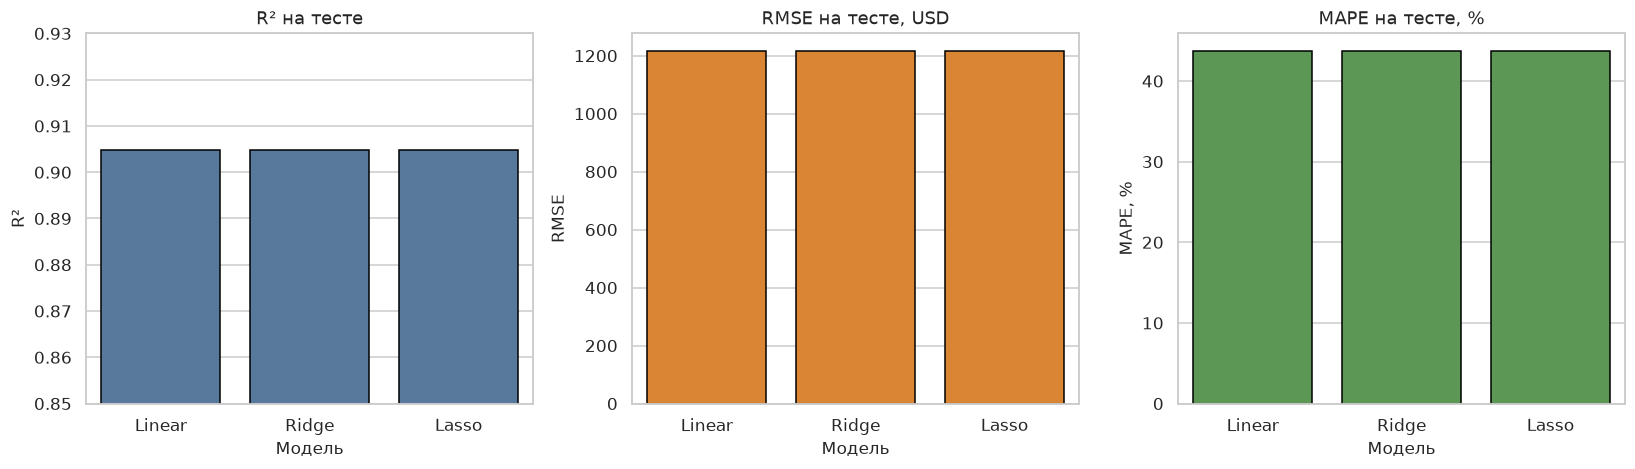

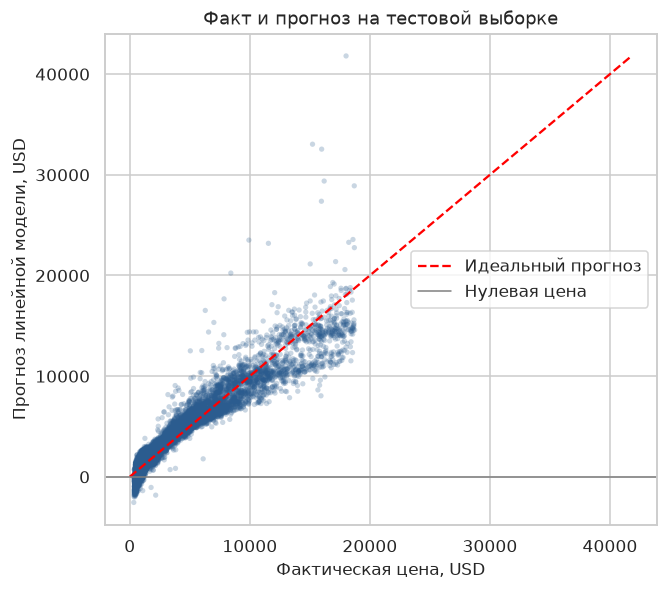

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
sns.barplot(data=results_orig, x="Модель", y="R2_Test", color="#4c78a8", edgecolor="black", ax=axes[0])
axes[0].set_ylim(0.85, 0.93)
axes[0].set_title("R² на тесте")
axes[0].set_ylabel("R²")
sns.barplot(data=results_orig, x="Модель", y="RMSE_Test", color="#f58518", edgecolor="black", ax=axes[1])
axes[1].set_title("RMSE на тесте, USD")
axes[1].set_ylabel("RMSE")
sns.barplot(data=results_orig, x="Модель", y="MAPE_Test_%", color="#54a24b", edgecolor="black", ax=axes[2])
axes[2].set_title("MAPE на тесте, %")
axes[2].set_ylabel("MAPE, %")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.2, 5.5))
ax.scatter(y_test, preds_orig["Linear"], alpha=0.25, s=12, edgecolor="none", color="#2b5c8f")
lims = [0, max(y_test.max(), preds_orig["Linear"].max())]
ax.plot(lims, lims, color="red", ls="--", lw=1.5, label="Идеальный прогноз")
ax.axhline(0, color="gray", lw=1, label="Нулевая цена")
ax.set_xlabel("Фактическая цена, USD")
ax.set_ylabel("Прогноз линейной модели, USD")
ax.set_title("Факт и прогноз на тестовой выборке")
ax.legend()
plt.tight_layout()
plt.show()

Столбцы трёх моделей на графиках метрик почти одной высоты: регуляризация при найденных \(\alpha\) не улучшает и не ухудшает прогноз. На диаграмме «факт — прогноз» точки ложатся вокруг диагонали, но облако расширяется с ростом цены. Дорогие камни чаще оказываются далеко от диагонали, а часть дешёвых уходит под горизонталь нулевой цены. Линейная модель хорошо держит общий наклон, но хуже описывает края диапазона. Это согласуется с выпуклостью облака «карат — цена» на этапе разведочного анализа.

### 4.1.1. Остатки и гомоскедастичность

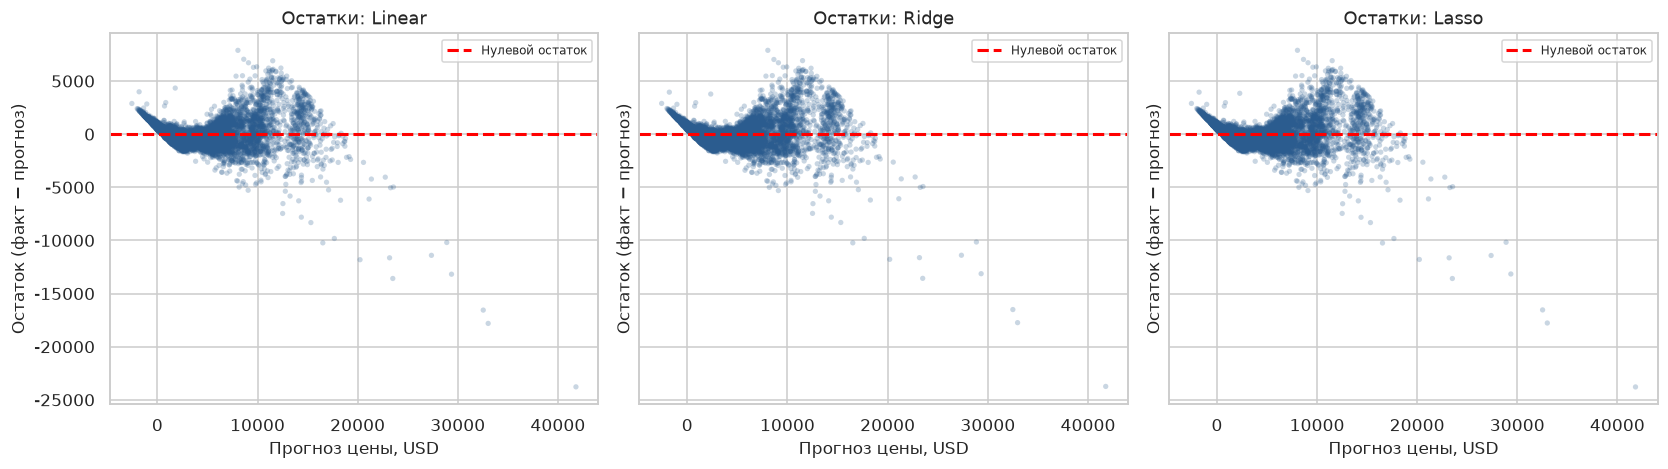

Тест Бройша–Пагана для линейной модели: LM = 2531.8, p-value = 0.000e+00
СКО остатков при прогнозе ниже медианы: 707.9 USD
СКО остатков при прогнозе выше медианы: 1562.0 USD


In [11]:
def plot_residuals(preds_dict, y_true, title_prefix):
    names = list(preds_dict.keys())
    fig, axes = plt.subplots(1, len(names), figsize=(5.1 * len(names), 4.4), sharey=True)
    if len(names) == 1:
        axes = [axes]
    y_true = np.asarray(y_true)
    for ax, name in zip(axes, names):
        y_hat = np.asarray(preds_dict[name])
        resid = y_true - y_hat
        ax.scatter(y_hat, resid, alpha=0.25, s=12, edgecolor="none", color="#2b5c8f")
        ax.axhline(0, color="red", ls="--", lw=2, label="Нулевой остаток")
        ax.set_xlabel("Прогноз цены, USD")
        ax.set_ylabel("Остаток (факт − прогноз)")
        ax.set_title(f"{title_prefix}: {name}")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_residuals(preds_orig, y_test, "Остатки")

resid_lin = y_test.to_numpy() - preds_orig["Linear"]
bp_stat, bp_pvalue, _, _ = het_breuschpagan(resid_lin, sm.add_constant(X_test_scaled))
print(f"Тест Бройша–Пагана для линейной модели: LM = {bp_stat:.1f}, p-value = {bp_pvalue:.3e}")

low = preds_orig["Linear"] <= np.median(preds_orig["Linear"])
print(f"СКО остатков при прогнозе ниже медианы: {resid_lin[low].std():.1f} USD")
print(f"СКО остатков при прогнозе выше медианы: {resid_lin[~low].std():.1f} USD")

Если дисперсия ошибок постоянна (гомоскедастичность), облако остатков — полоса примерно одинаковой ширины вокруг горизонтали \(e = 0\). Здесь полосы нет. Слева, у небольших прогнозов, точки собраны теснее, справа разброс растёт, и появляются крупные отрицательные остатки: модель занижает цену самых дорогих камней. СКО остатков выше медианы прогноза примерно вдвое больше, чем ниже медианы.

Тест Бройша–Пагана формально отвергает гомоскедастичность: p-value практически равен нулю. На выборке в десять тысяч наблюдений тест чувствителен, но здесь он согласован с графиком, а не спорит с ним. Структура ошибок — гетероскедастичность. Отдельные прогнозы на графике доходят примерно до 40 тысяч долларов, хотя самый дорогой камень в данных стоит около 19 тысяч. Так проявляется неустойчивость коэффициентов при размерах: небольшое расхождение массы и миллиметров умножается на веса в несколько тысяч долларов. Она связана с асимметрией цены, а не с тем, какую из трёх линейных моделей выбрать: Linear, Ridge и Lasso дают одну и ту же картину.

Гетероскедастичность не отменяет R², но меняет смысл ошибки. Доверительные интервалы обычного МНК в такой ситуации слишком узкие, а RMSE в основном отражает промахи на дорогих камнях. Типичный следующий шаг — логарифм цены. Он будет проверен отдельно, после сравнения с PCA, чтобы не смешивать две разные поправки.

,Признак,Linear,Ridge,Lasso
0,carat,5276.2,5253.8,5265.1
1,cut_score,147.4,145.9,145.8
2,color_score,555.2,554.8,554.8
3,clarity_score,818.3,819.8,819.3
4,depth,72.4,60.6,58.5
5,table,-40.9,-43.2,-42.9
6,x,-2141.7,-1943.0,-1992.7
7,y,2510.2,2241.6,2268.7
8,z,-1514.7,-1421.8,-1410.4


Свободный член (средняя цена обучающей выборки, USD): 3938.5
Нулевых коэффициентов Lasso: 0


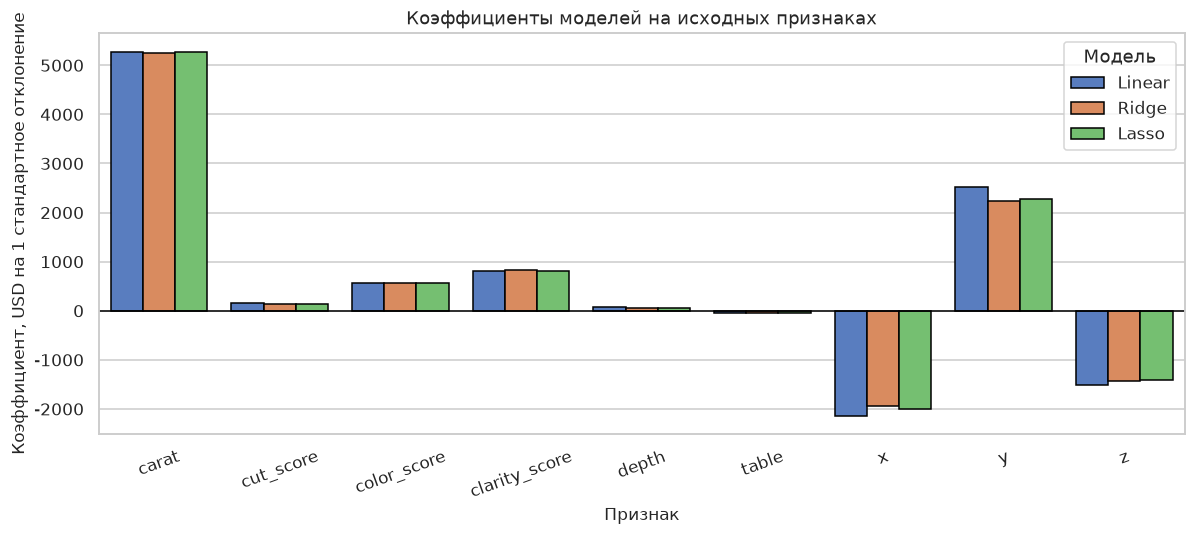

In [12]:
coef_df = pd.DataFrame({
    "Признак": feature_cols,
    "Linear": fitted_orig["Linear"].coef_,
    "Ridge": fitted_orig["Ridge"].coef_,
    "Lasso": fitted_orig["Lasso"].coef_,
})
display(coef_df.round(1))
print("Свободный член (средняя цена обучающей выборки, USD):", round(fitted_orig["Linear"].intercept_, 1))
print("Нулевых коэффициентов Lasso:", int(np.sum(np.abs(fitted_orig["Lasso"].coef_) < 1e-8)))

coef_long = coef_df.melt(id_vars="Признак", var_name="Модель", value_name="Коэффициент")
plt.figure(figsize=(11, 5))
sns.barplot(data=coef_long, x="Признак", y="Коэффициент", hue="Модель", edgecolor="black")
plt.axhline(0, color="black", lw=1)
plt.xticks(rotation=20)
plt.ylabel("Коэффициент, USD на 1 стандартное отклонение")
plt.title("Коэффициенты моделей на исходных признаках")
plt.tight_layout()
plt.show()

Свободный член около 3 938 долларов — это средняя цена обучающей выборки, потому что признаки стандартизированы и их среднее на train равно нулю.

Содержательно коэффициенты делятся на две группы. Баллы качества положительны: при той же комбинации остальных признаков более высокая огранка, лучший цвет и более высокая чистота увеличивают прогноз. Это исправляет обманчивые отрицательные корреляции из раздела 3.2. Масса тоже входит с большим положительным весом, около 5 300 долларов на одно своё стандартное отклонение.

Коэффициенты `x`, `y` и `z` читать по отдельности нельзя. Все три размера положительно коррелируют с ценой, но в модели знак у длины и глубины отрицательный, а у ширины положительный, и модули составляют тысячи долларов. Так выглядит дележка одного и того же эффекта размера между почти линейно зависимыми столбцами. VIF в сотни как раз предупреждал об этом.

Ridge немного подтягивает эти веса друг к другу, но знаки не выравнивает: штраф слишком мал. Lasso не обнулил ни одного коэффициента. Отбора признаков не произошло, потому что кросс-валидация оптимизирует прогноз, а прогноз от удаления одного из размеров почти не страдает — оставшиеся размеры его дублируют. Регуляризация здесь стабилизирует решение лишь слегка и не заменяет содержательное устранение мультиколлинеарности.

### 4.2. Устранение мультиколлинеарности методом главных компонент

PCA строится по уже стандартизированной обучающей матрице. Каждая главная компонента — новая ось, на которую исходные признаки проецируются так, чтобы оси были некоррелированы и шли по убыванию дисперсии. Число компонент выбирается по двум обычным правилам: критерий Кайзера (оставлять компоненты с собственным значением больше 1) и накопленная доля дисперсии (не меньше 90%). Если критерий Кайзера оставляет слишком мало дисперсии, берётся порог 90%.

In [13]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
eigenvalues = pca_full.explained_variance_
exp_var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var_ratio)

k_kaiser = int((eigenvalues > 1.0).sum())
k_90 = int(np.searchsorted(cum_var, 0.90) + 1)
k_opt = k_kaiser if cum_var[k_kaiser - 1] >= 0.90 else k_90

pca_table = pd.DataFrame({
    "Компонента": [f"PC{i + 1}" for i in range(len(eigenvalues))],
    "Собственное значение": eigenvalues,
    "Доля дисперсии": exp_var_ratio,
    "Накопленная доля": cum_var,
})
display(pca_table.round(4))
print(f"Критерий Кайзера: k = {k_kaiser}, накопленная дисперсия = {cum_var[k_kaiser - 1]:.1%}")
print(f"Порог 90% дисперсии: k = {k_90}, накопленная дисперсия = {cum_var[k_90 - 1]:.1%}")
print(f"Для моделей выбрано k = {k_opt}")

,Компонента,Собственное значение,Доля дисперсии,Накопленная доля
0,PC1,4.2958,0.4773,0.4773
1,PC2,1.4103,0.1567,0.6340
2,PC3,1.2264,0.1363,0.7703
3,PC4,0.9857,0.1095,0.8798
4,PC5,0.6919,0.0769,0.9567
5,PC6,0.3571,0.0397,0.9963
6,PC7,0.0299,0.0033,0.9997
7,PC8,0.0018,0.0002,0.9999
8,PC9,0.0012,0.0001,1.0000


Критерий Кайзера: k = 3, накопленная дисперсия = 77.0%
Порог 90% дисперсии: k = 5, накопленная дисперсия = 95.7%
Для моделей выбрано k = 5


Первая компонента забирает около 48% дисперсии, вторая и третья — ещё примерно по 14–16%. Дальше вклад падает. Критерий Кайзера оставляет только три компоненты: у четвёртой собственное значение уже меньше 1 (около 0,99). Вместе эти три оси объясняют около 77% дисперсии признаков. Для описания данных этого мало, и ниже по зависимости R² от числа компонент будет видно, что для цены трёх осей тоже не хватает.

Порог 90% достигается на пятой компоненте. После четырёх компонент накоплено около 88%, после пяти — около 95,7%. Пятая компонента поэтому одновременно пересекает и 90%, и 95%. В модели дальше используются 5 главных компонент: это сокращение с 9 признаков до 5 и при этом сохранение почти всей дисперсии признаков. Критерий Кайзера здесь слишком жёсткий, его результат оставлен в таблице как ориентир, но не как итоговое \(k\).

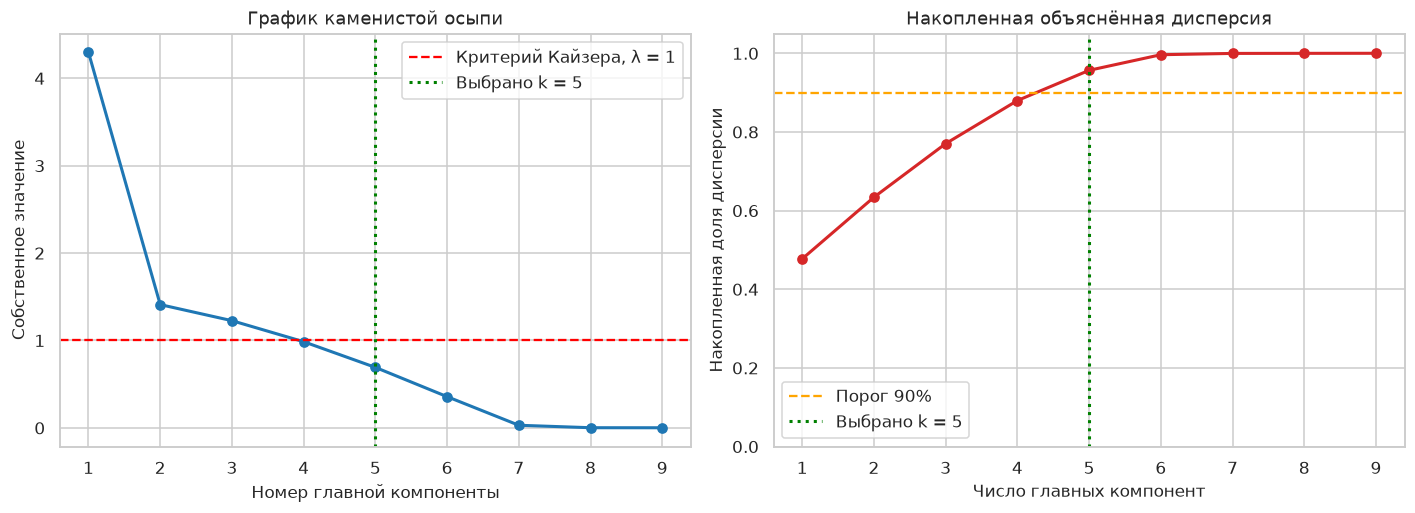

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
xs = np.arange(1, len(eigenvalues) + 1)
axes[0].plot(xs, eigenvalues, "o-", color="#1f77b4", lw=2)
axes[0].axhline(1.0, color="red", ls="--", lw=1.5, label="Критерий Кайзера, λ = 1")
axes[0].axvline(k_opt, color="green", ls=":", lw=2, label=f"Выбрано k = {k_opt}")
axes[0].set_xticks(xs)
axes[0].set_xlabel("Номер главной компоненты")
axes[0].set_ylabel("Собственное значение")
axes[0].set_title("График каменистой осыпи")
axes[0].legend()

axes[1].plot(xs, cum_var, "o-", color="#d62728", lw=2)
axes[1].axhline(0.90, color="orange", ls="--", label="Порог 90%")
axes[1].axvline(k_opt, color="green", ls=":", lw=2, label=f"Выбрано k = {k_opt}")
axes[1].set_xticks(xs)
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Число главных компонент")
axes[1].set_ylabel("Накопленная доля дисперсии")
axes[1].set_title("Накопленная объяснённая дисперсия")
axes[1].legend()
plt.tight_layout()
plt.show()

На графике осыпи излом заметен после третьей компоненты: дальше собственные значения уходят под линию \(\lambda = 1\) и убывают плавно, без второго резкого обрыва. Если смотреть только на «локоть», хочется остановиться на трёх осях. Кумулятивная кривая справа показывает цену такой остановки: за бортом остаётся больше 20% дисперсии. Зелёная линия стоит на \(k = 5\), где накопленная доля уже выше 95%.

Осыпь отвечает на вопрос «где кончается крупная структура признаков», а не на вопрос «сколько осей нужно, чтобы предсказать цену». Эти вопросы совпадают не всегда. Проверка ниже как раз отделяет долю дисперсии от качества прогноза.

,PC1,PC2,PC3,PC4,PC5
carat,0.471,-0.092,-0.032,0.012,0.125
cut_score,-0.107,-0.607,-0.434,0.237,-0.182
color_score,-0.158,0.200,0.015,0.804,0.536
clarity_score,-0.221,-0.216,-0.212,-0.504,0.777
depth,0.011,-0.184,0.833,-0.067,0.120
table,0.128,0.692,-0.246,-0.183,0.024
x,0.475,-0.078,-0.071,0.045,0.114
y,0.475,-0.081,-0.073,0.044,0.120
z,0.474,-0.102,0.031,0.036,0.132


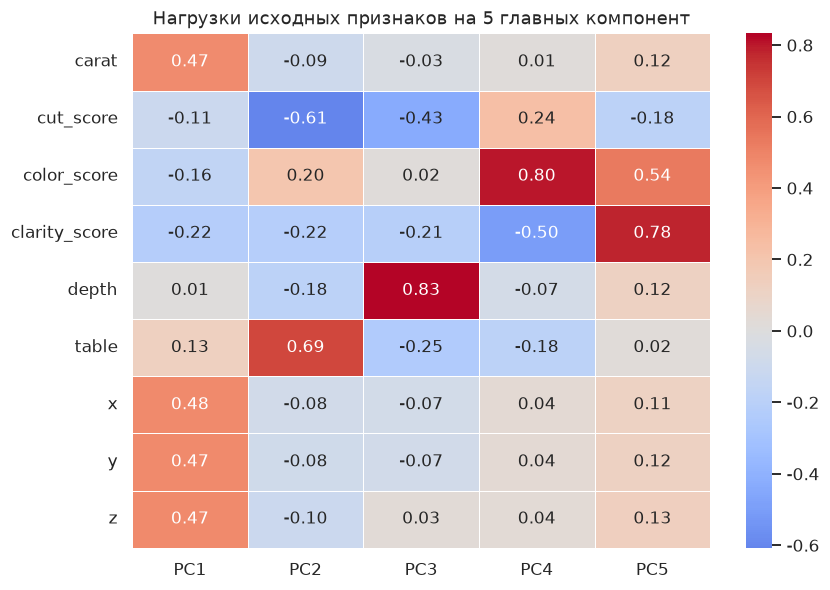

Максимальная |корреляция| между разными PC: 3.226168064438164e-16
VIF главных компонент: [1. 1. 1. 1. 1.]


In [15]:
pca = PCA(n_components=k_opt, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=[f"PC{i + 1}" for i in range(k_opt)],
)
display(loadings.round(3))

plt.figure(figsize=(8, 5.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4)
plt.title(f"Нагрузки исходных признаков на {k_opt} главных компонент")
plt.tight_layout()
plt.show()

pc_corr = np.corrcoef(X_train_pca.T)
print("Максимальная |корреляция| между разными PC:", float(np.max(np.abs(pc_corr - np.eye(k_opt)))))
vif_pc = [variance_inflation_factor(X_train_pca, i) for i in range(k_opt)]
print("VIF главных компонент:", np.round(vif_pc, 4))

Нагрузки читаются по столбцам.

- PC1 — фактор размера. На неё с весом около 0,47 входят масса и все три миллиметра. Это половина всей дисперсии признаков.
- PC2 противопоставляет огранку и ширину площадки: у хорошей огранки площадка обычно меньше.
- PC3 в основном про процентную глубину.
- PC4 и PC5 разбирают качество камня: цвет и чистоту, которые в первую компоненту почти не попали.

Корреляции между компонентами на обучающей выборке равны нулю с точностью до ошибки округления, VIF каждой компоненты равен 1. Мультиколлинеарность в новом пространстве снята по построению метода: ортогональные оси нельзя линейно восстановить друг через друга. Тест проецируется тем преобразованием, которое настроено на train, без повторного подбора осей.

,k,Накопленная дисперсия,R2_Test,RMSE_Test,MAPE_Test_%
0,1,0.4773,0.7369,2021.7704,65.4453
1,2,0.6340,0.7641,1914.3788,62.7454
2,3,0.7703,0.7746,1871.2816,62.7485
3,4,0.8798,0.7751,1869.1257,62.9921
4,5,0.9567,0.8629,1459.3151,67.8033
5,6,0.9963,0.8630,1458.6926,67.8613
6,7,0.9997,0.9036,1223.8231,43.8362
7,8,0.9999,0.9039,1221.8410,43.7580
8,9,1.0000,0.9048,1215.8000,43.6881


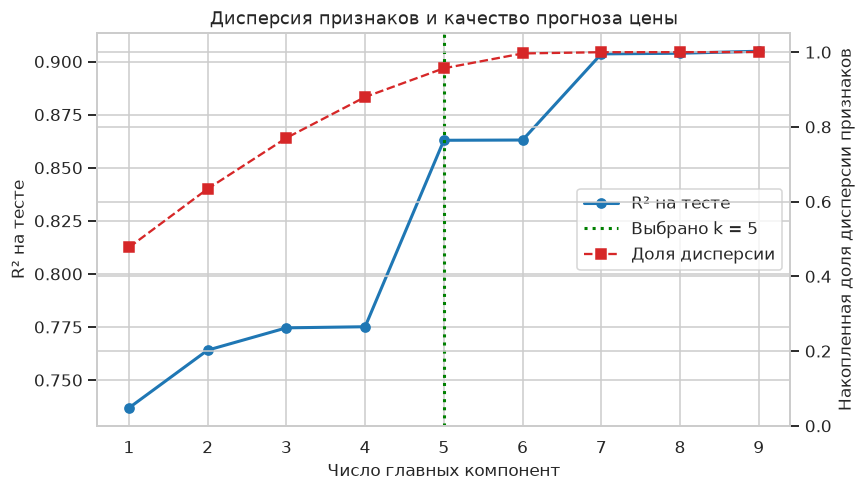

,нагрузка PC7
carat,0.868
cut_score,-0.006
color_score,0.019
clarity_score,-0.015
depth,-0.017
table,-0.013
x,-0.274
y,-0.294
z,-0.291


In [16]:
rows_k = []
for k in range(1, X_train_scaled.shape[1] + 1):
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    Z_tr = pca_k.fit_transform(X_train_scaled)
    Z_te = pca_k.transform(X_test_scaled)
    pred_k = LinearRegression().fit(Z_tr, y_train).predict(Z_te)
    rows_k.append({
        "k": k,
        "Накопленная дисперсия": cum_var[k - 1],
        "R2_Test": r2_score(y_test, pred_k),
        "RMSE_Test": np.sqrt(mean_squared_error(y_test, pred_k)),
        "MAPE_Test_%": mean_absolute_percentage_error(y_test, pred_k) * 100,
    })
k_quality = pd.DataFrame(rows_k)
display(k_quality.round(4))

fig, ax1 = plt.subplots(figsize=(8, 4.6))
ax1.plot(k_quality["k"], k_quality["R2_Test"], "o-", color="#1f77b4", lw=2, label="R² на тесте")
ax1.axvline(k_opt, color="green", ls=":", lw=2, label=f"Выбрано k = {k_opt}")
ax1.set_xlabel("Число главных компонент")
ax1.set_ylabel("R² на тесте")
ax1.set_xticks(k_quality["k"])
ax2 = ax1.twinx()
ax2.plot(k_quality["k"], k_quality["Накопленная дисперсия"], "s--", color="#d62728", lw=1.5, label="Доля дисперсии")
ax2.set_ylabel("Накопленная доля дисперсии признаков")
ax2.set_ylim(0, 1.05)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")
ax1.set_title("Дисперсия признаков и качество прогноза цены")
plt.tight_layout()
plt.show()

pca7 = PCA(n_components=7, random_state=RANDOM_STATE).fit(X_train_scaled)
pc7 = pd.Series(pca7.components_[6], index=feature_cols, name="нагрузка PC7")
display(pc7.to_frame().round(3))

Таблица показывает, что доля дисперсии и точность прогноза идут не рядом.

До четырёх компонент R² на тесте остаётся около 0,74–0,78. Пятая компонента, на которой как раз сидят цвет и чистота, поднимает R² до 0,863. Шестая почти ничего не добавляет. Седьмая объясняет лишь около 0,3% дисперсии признаков, но поднимает R² до 0,904 — то есть почти до уровня модели на всех девяти столбцах. Её нагрузки устроены как контраст: масса входит с большим плюсом (около 0,87), а `x`, `y` и `z` — с минусом около 0,28. Это остаток «тяжелее или легче, чем обещают миллиметры». Дисперсия такого остатка крошечная, потому что карат и размеры почти совпадают, но для цены именно он полезен.

Отсюда прямое ограничение PCA в этой задаче. Метод сохраняет разброс признаков, а не связь с ценой. Правило 90% честно сокращает описание камня и убирает коллинеарность, но выбрасывает слабую по дисперсии ось, которая регрессии нужна. Ниже модели обучаются именно при \(k = 5\), как решено по накопленной дисперсии, чтобы сравнение «до и после» отвечало этому правилу, а не подгонке \(k\) под максимальный R².

### 4.3. Регрессия на главных компонентах

Те же три алгоритма обучаются на пяти компонентах. Штраф Ridge и Lasso заново подбирается кросс-валидацией уже в новом пространстве: переносить старые \(\alpha\) было бы некорректно, потому что набор столбцов другой. Метрики считаются по исходной цене в долларах, а не по координатам компонент.

In [17]:
ridge_pca_cv = RidgeCV(alphas=alphas, cv=5).fit(X_train_pca, y_train)
lasso_pca_cv = LassoCV(alphas=alphas, cv=5, random_state=RANDOM_STATE, max_iter=20000).fit(X_train_pca, y_train)
print(f"Ridge на PC: alpha = {float(ridge_pca_cv.alpha_):.4f}")
print(f"Lasso на PC: alpha = {float(lasso_pca_cv.alpha_):.4f}")

models_pca = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=float(ridge_pca_cv.alpha_), random_state=RANDOM_STATE),
    "Lasso": Lasso(alpha=float(lasso_pca_cv.alpha_), random_state=RANDOM_STATE, max_iter=20000),
}
results_pca, fitted_pca, preds_pca = evaluate_models(
    models_pca, X_train_pca, X_test_pca, y_train, y_test,
    space_name=f"Главные компоненты ({k_opt})",
)
display(results_pca.round(4))

Ridge на PC: alpha = 5.7362
Lasso на PC: alpha = 0.1083
Linear   | R2(CV)=0.8634±0.0012 | R2(test)=0.8629 | RMSE=1459.3 | MAPE=67.80% | отриц. прогнозов=1729
Ridge    | R2(CV)=0.8634±0.0012 | R2(test)=0.8629 | RMSE=1459.3 | MAPE=67.79% | отриц. прогнозов=1729
Lasso    | R2(CV)=0.8634±0.0012 | R2(test)=0.8629 | RMSE=1459.3 | MAPE=67.80% | отриц. прогнозов=1729


,Модель,Пространство,R2_CV,R2_CV_std,R2_Test,RMSE_Test,MAPE_Test_%,Отрицательных прогнозов
0,Linear,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3151,67.8033,1729
1,Ridge,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3099,67.7930,1729
2,Lasso,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3106,67.7963,1729


На главных компонентах три модели снова совпали между собой. Ортогональным признакам штраф почти не нужен: мультиколлинеарности, с которой Ridge и Lasso борются на исходных данных, здесь уже нет. Поэтому линейная регрессия, гребень и лассо дают один и тот же тест.

Само качество ниже, чем на исходных признаках. R² опускается примерно с 0,905 до 0,863, RMSE вырастает примерно с 1 216 до 1 459 долларов, MAPE — примерно с 44% до 68%. Кросс-валидационный R² (около 0,863) совпадает с тестовым, просадки из-за неудачного фолда нет. Потеря связана с составом признаков: пять компонент не включают контраст массы и размеров, который таблица по \(k\) показала на седьмой оси.

Отрицательные прогнозы при этом никуда не делись. PCA меняет координаты признаков, но целевая переменная по-прежнему сырая цена, и линейная формула по-прежнему может уйти ниже нуля.

### 4.3.1. Остатки моделей на главных компонентах

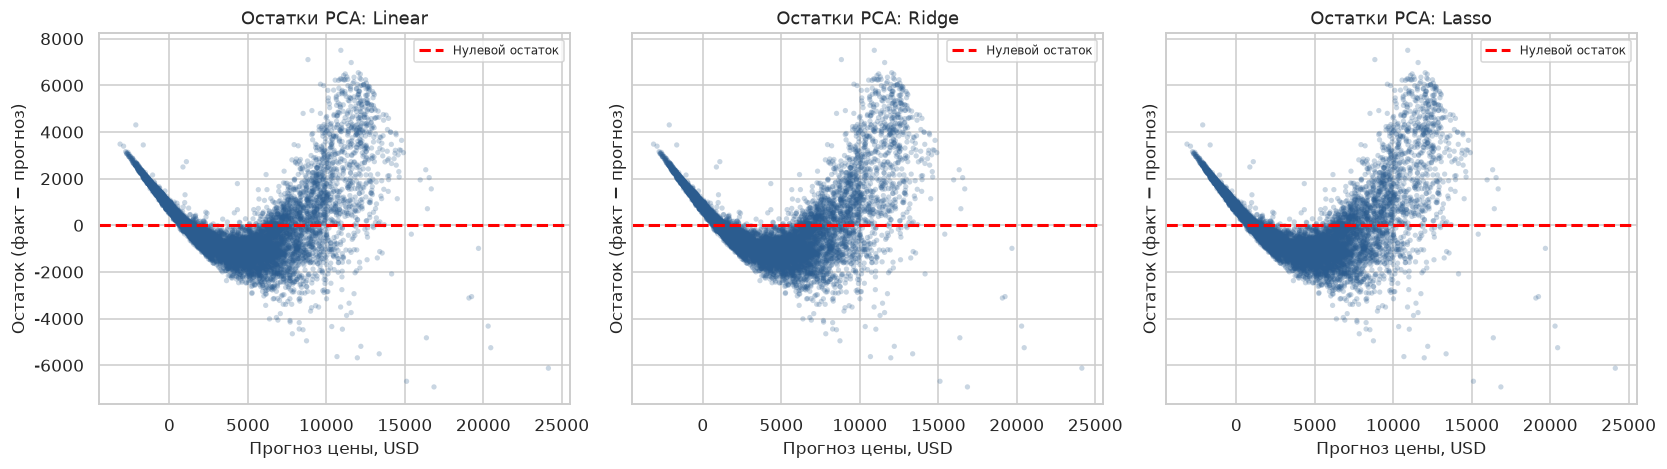

Тест Бройша–Пагана после PCA: p-value = 0.000e+00
СКО остатков ниже медианы прогноза: 998.0 USD
СКО остатков выше медианы прогноза: 1760.9 USD


In [18]:
plot_residuals(preds_pca, y_test, "Остатки PCA")

resid_pca = y_test.to_numpy() - preds_pca["Linear"]
_, bp_pvalue_pca, _, _ = het_breuschpagan(resid_pca, sm.add_constant(X_test_pca))
low_pca = preds_pca["Linear"] <= np.median(preds_pca["Linear"])
print(f"Тест Бройша–Пагана после PCA: p-value = {bp_pvalue_pca:.3e}")
print(f"СКО остатков ниже медианы прогноза: {resid_pca[low_pca].std():.1f} USD")
print(f"СКО остатков выше медианы прогноза: {resid_pca[~low_pca].std():.1f} USD")

Картина остатков после PCA та же по характеру и чуть хуже по ширине. Горизонталь \(e = 0\) по-прежнему не является осью симметричной полосы: разброс растёт вместе с прогнозом, тест Бройша–Пагана снова отвергает постоянную дисперсию. СКО остатков в дорогой половине прогноза по-прежнему заметно больше, чем в дешёвой.

Это ожидаемое разделение двух разных дефектов. PCA убрал корреляцию между предикторами. Неоднородная дисперсия ошибки сидит в целевой переменной: дорогие камни отличаются от дешёвых на тысячи долларов, дешёвые — на сотни. Никакая перестановка столбцов X этого не отменяет. Путать «мультиколлинеарность вылечена» и «модель стала гомоскедастичной» по этим графикам нельзя.

### 4.4. Сравнение метрик до и после PCA

,Модель,Пространство,R2_CV,R2_CV_std,R2_Test,RMSE_Test,MAPE_Test_%
0,Lasso,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3106,67.7963
1,Linear,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3151,67.8033
2,Ridge,Главные компоненты (5),0.8634,0.0012,0.8629,1459.3099,67.7930
3,Lasso,Исходные признаки,0.9087,0.0028,0.9048,1215.8126,43.6861
4,Linear,Исходные признаки,0.9087,0.0028,0.9048,1215.8000,43.6881
5,Ridge,Исходные признаки,0.9087,0.0028,0.9049,1215.6691,43.7160


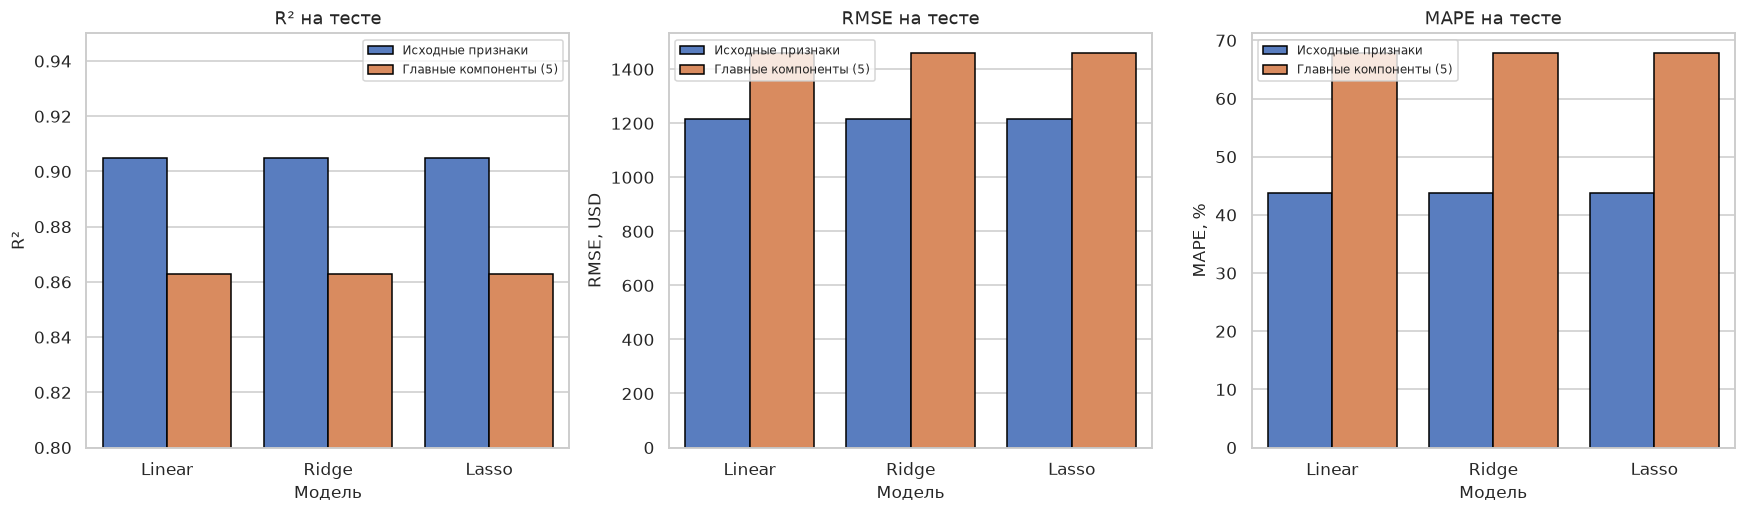

Лучший R²: Ridge, Исходные признаки, R2=0.9049, RMSE=1215.7, MAPE=43.72%


In [19]:
summary = pd.concat([results_orig, results_pca], ignore_index=True)
summary_view = summary.drop(columns=["Отрицательных прогнозов"]).sort_values(
    ["Пространство", "Модель"]
).reset_index(drop=True)
display(summary_view.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.barplot(data=summary, x="Модель", y="R2_Test", hue="Пространство", edgecolor="black", ax=axes[0])
axes[0].set_title("R² на тесте")
axes[0].set_ylabel("R²")
axes[0].set_ylim(0.8, 0.95)
sns.barplot(data=summary, x="Модель", y="RMSE_Test", hue="Пространство", edgecolor="black", ax=axes[1])
axes[1].set_title("RMSE на тесте")
axes[1].set_ylabel("RMSE, USD")
sns.barplot(data=summary, x="Модель", y="MAPE_Test_%", hue="Пространство", edgecolor="black", ax=axes[2])
axes[2].set_title("MAPE на тесте")
axes[2].set_ylabel("MAPE, %")
for ax in axes:
    ax.legend(fontsize=8, title="")
plt.tight_layout()
plt.show()

best = summary.sort_values("R2_Test", ascending=False).iloc[0]
print(
    f"Лучший R²: {best['Модель']}, {best['Пространство']}, "
    f"R2={best['R2_Test']:.4f}, RMSE={best['RMSE_Test']:.1f}, MAPE={best['MAPE_Test_%']:.2f}%"
)

Сравнение однозначное. На исходных признаках R² выше примерно на 0,04, RMSE ниже примерно на 240 долларов, MAPE ниже примерно на 24 процентных пункта. Внутри каждого пространства Linear, Ridge и Lasso не различаются. Регуляризация не дала выигрыша ни до PCA, ни после: в первом случае кросс-валидация взяла маленький штраф, во втором штрафовать было уже нечего.

PCA при этом сделал ровно ту работу, для которой его здесь применяли. Девять признаков, из которых четыре были почти копиями друг друга, заменены пятью некоррелированными компонентами с VIF = 1. Интерпретация осей стала чище: размер, пропорции огранки, глубина, цвет и чистота больше не смешаны в одной группе коэффициентов с противоречивыми знаками.

Цена этого упрощения — потеря прогноза. Правило накопленной дисперсии не видело седьмую компоненту, а именно она возвращала точность полной модели. Для отчёта честнее оставить \(k = 5\) и зафиксировать ухудшение метрик, чем увеличивать \(k\), пока таблица «до и после» не станет одинаковой. Если цель — только точный прогноз цены, исходные признаки с гребневой регрессией предпочтительнее. Если цель — устойчивое описание факторов, предпочтительнее компоненты, но тогда ошибку нужно принимать больше.

Лучшая строка по R² — любая из трёх моделей на исходных признаках (различие в четвёртом знаке). Практически это одна и та же модель.

### 4.5. Что может повысить точность

Предыдущие разделы отвечают на обязательное сравнение. Отдельно стоит проверить две идеи, которые сами графики уже подсказали.

Первая идея — не лечить коллинеарность методом PCA, а убрать лишние размеры руками: оставить массу и выкинуть `x`, `y`, `z`, потому что они дублируют карат. Вторая идея относится не к столбцам X, а к цене: обучить линейную регрессию на \(\ln(\text{price})\) и перед расчётом RMSE, R² и MAPE вернуть прогноз в доллары через экспоненту. Метрики по-прежнему считаются против фактической цены, а не против логарифма.

Без x, y, z | R2=0.9021 | RMSE=1232.9 | MAPE=49.07%


,Признак,Коэффициент
0,carat,4174.0
1,cut_score,138.6
2,color_score,545.3
3,clarity_score,865.1
4,depth,-64.1
5,table,-56.7


Модель ln(price), метрики в долларах | R2=0.9505 | RMSE=876.8 | MAPE=11.53% | мин. прогноз=290.5 | отрицательных=0
СКО логарифмических остатков ниже медианы: 0.147
СКО логарифмических остатков выше медианы: 0.151


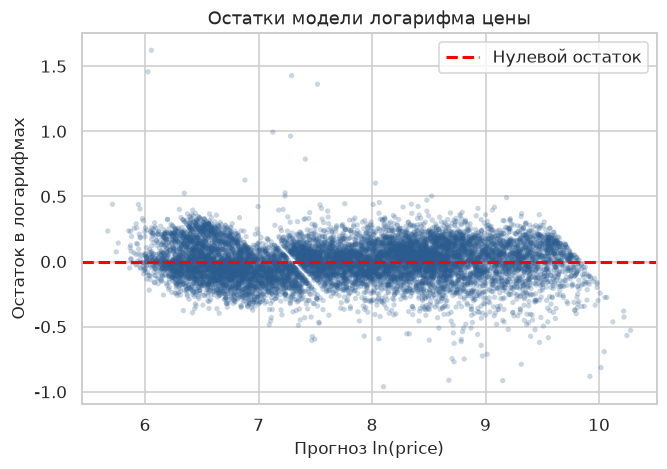

In [20]:
reduced_cols = ["carat", "cut_score", "color_score", "clarity_score", "depth", "table"]
X_tr_red = X_train[reduced_cols]
X_te_red = X_test[reduced_cols]
scaler_red = StandardScaler()
X_tr_red_s = scaler_red.fit_transform(X_tr_red)
X_te_red_s = scaler_red.transform(X_te_red)
lin_red = LinearRegression().fit(X_tr_red_s, y_train)
pred_red = lin_red.predict(X_te_red_s)
print(
    "Без x, y, z | "
    f"R2={r2_score(y_test, pred_red):.4f} | "
    f"RMSE={np.sqrt(mean_squared_error(y_test, pred_red)):.1f} | "
    f"MAPE={mean_absolute_percentage_error(y_test, pred_red) * 100:.2f}%"
)
display(pd.DataFrame({"Признак": reduced_cols, "Коэффициент": lin_red.coef_}).round(1))

lin_log = LinearRegression().fit(X_train_scaled, np.log(y_train))
pred_log_dollar = np.exp(lin_log.predict(X_test_scaled))
print(
    "Модель ln(price), метрики в долларах | "
    f"R2={r2_score(y_test, pred_log_dollar):.4f} | "
    f"RMSE={np.sqrt(mean_squared_error(y_test, pred_log_dollar)):.1f} | "
    f"MAPE={mean_absolute_percentage_error(y_test, pred_log_dollar) * 100:.2f}% | "
    f"мин. прогноз={pred_log_dollar.min():.1f} | "
    f"отрицательных={(pred_log_dollar < 0).sum()}"
)

resid_log = np.log(y_test.to_numpy()) - lin_log.predict(X_test_scaled)
log_hat = lin_log.predict(X_test_scaled)
low_log = log_hat <= np.median(log_hat)
print(f"СКО логарифмических остатков ниже медианы: {resid_log[low_log].std():.3f}")
print(f"СКО логарифмических остатков выше медианы: {resid_log[~low_log].std():.3f}")

fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(log_hat, resid_log, alpha=0.25, s=12, edgecolor="none", color="#2b5c8f")
ax.axhline(0, color="red", ls="--", lw=2, label="Нулевой остаток")
ax.set_xlabel("Прогноз ln(price)")
ax.set_ylabel("Остаток в логарифмах")
ax.set_title("Остатки модели логарифма цены")
ax.legend()
plt.tight_layout()
plt.show()

Удаление `x`, `y` и `z` почти не портит R²: около 0,902 против 0,905 у полной модели. RMSE вырастает примерно до 1 233 долларов, MAPE — примерно до 49%. Зато коэффициенты становятся читаемыми. Масса, огранка, цвет и чистота входят с плюсом, глубина и площадка — с небольшим минусом. Противоречивых знаков у трёх размеров больше нет, потому что самих размеров в модели нет. Это более простой способ снять мультиколлинеарность, чем PCA, и для прогноза он точнее пяти главных компонент. PCA остаётся полезен, когда признаков много и вручную не видно, какие из них дублируют друг друга. Здесь дублирование было видно уже по корреляциям 0,98.

Логарифм цены меняет качество сильнее, чем любая перестановка признаков. После возврата в доллары R² около 0,95, RMSE около 877 долларов, MAPE около 11,5%. Минимальный прогноз на тесте около 290 долларов, отрицательных цен нет: экспонента этого не допускает. В логарифмической шкале СКО остатков в дешёвой и дорогой половине прогноза почти одинаково (около 0,15), и облако вокруг нулевой линии больше похоже на полосу, чем веер долларовых остатков. Формальный тест на большой выборке всё ещё может быть слишком строгим, но практическая гетероскедастичность, которая определяла графики в разделах 4.1 и 4.3, здесь снята.

Именно логарифм, а не PCA, отвечает на вопрос, как уменьшить ошибку. PCA отвечал на другой вопрос — как получить некоррелированные факторы.

## 5. Заключение

На данных о ценах бриллиантов пройден полный цикл линейной регрессии: загрузка и разведочный анализ, очистка, порядковое кодирование качества, корреляции, VIF, три модели с кросс-валидацией, разбор остатков, PCA и повторное обучение.

1. Цена в первую очередь определяется размером камня. Корреляция массы с ценой около 0,92, и уже одна эта связь даёт линейной модели высокий R². Качество огранки, цвет и чистота в сырых корреляциях выглядят слабыми или отрицательными только потому, что лучшие камни в выборке мельче. В регрессии, где масса контролируется, их коэффициенты положительны.
2. Мультиколлинеарность сильная и понятная по происхождению. Масса и три линейных размера коррелируют на 0,98–0,99, VIF размеров измеряется сотнями. Коэффициенты МНК при `x`, `y` и `z` получают противоположные знаки и не интерпретируются. Гребневая регрессия и лассо при \(\alpha\), выбранных кросс-валидацией, почти не отличаются от МНК: прогноз они не портят и не улучшают, а знаки размеров не исправляют.
3. На исходных признаках тестовые метрики трёх моделей совпадают: R² около 0,905, RMSE около 1 216 долларов, MAPE около 44%. Высокий R² и высокий MAPE не противоречат друг другу. Квадратичная ошибка смотрит на дорогие камни, процентная — на дешёвые. Около 8% прогнозов отрицательны.
4. Остатки гетероскедастичны. Облако расширяется вдоль прогноза, линия \(e = 0\) это только подчёркивает, тест Бройша–Пагана отвергает постоянную дисперсию. Та же структура сохраняется после PCA. Сжатие признаков не лечит форму ошибки цены.
5. После стандартизации PCA сводит 9 признаков к 5 некоррелированным компонентам с VIF = 1 и около 95,7% дисперсии. Первая компонента — размер, следующие описывают пропорции и качество. Метрики при этом хуже: R² около 0,863, RMSE около 1 459 долларов, MAPE около 68%. Причина не в неудачном обучении, а в критерии отбора. Седьмая компонента несёт контраст массы и миллиметров, объясняет доли процента дисперсии и почти целиком возвращает точность полной модели. PCA максимизирует дисперсию признаков, а не R².
6. Точность поднимает логарифм цены, а не смена линейного алгоритма. Модель \(\ln(\text{price})\) на тех же признаках даёт на тесте R² около 0,95, RMSE около 880 долларов и MAPE около 11,5%, без отрицательных прогнозов. Если нужно просто убрать коллинеарность и сохранить смысл коэффициентов, достаточно оставить карат и удалить `x`, `y`, `z`: R² остаётся около 0,90.

Итог лабораторной работы: на этих данных линейная регрессия хорошо предсказывает цену, но коэффициенты размера неустойчивы из-за мультиколлинеарности. PCA эту мультиколлинеарность устраняет и снижает размерность, однако при отборе компонент по доле дисперсии точность падает. Гребень и лассо при честном подборе штрафа здесь почти эквивалентны обычному МНК.

## 6. Список источников

1. Shivam Agrawal. *Diamonds* (набор характеристик и цен бриллиантов). Kaggle.
   https://www.kaggle.com/datasets/shivam2503/diamonds
   Исходная версия набора распространяется с пакетом ggplot2: Wickham H. *ggplot2: Elegant Graphics for Data Analysis*. Springer.
2. Pedregosa F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2011.
   https://scikit-learn.org/stable/
3. James G., Witten D., Hastie T., Tibshirani R. *An Introduction to Statistical Learning*. Springer.
   https://www.statlearning.com/
4. Hastie T., Tibshirani R., Friedman J. *The Elements of Statistical Learning*. Springer.
   Главы о гребневой регрессии, лассо и методе главных компонент.
5. Jolliffe I. T., Cadima J. Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A*, 2016.
6. Документация pandas: https://pandas.pydata.org/docs/
7. Расчёт VIF в statsmodels:
   https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html
8. Тест Бройша–Пагана в statsmodels:
   https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_breuschpagan.html

## 7. Приложение

Полный листинг программы находится в ячейках кода этого ноутбука, в том порядке, в котором выполнялся анализ. Результаты расчётов и графики сохранены вместе с кодом. Отдельный скрипт не прикладывается: пояснение стоит сразу после ячейки, которая загружает данные, считает метрики или строит график.